# DSEG-LIME baseline on RVL-CDIP documents: ResNet-101 classifier

Same notebook as `dseg_lime_rvlcdip_dit.ipynb`, but the classifier being explained is a **ResNet-101 fine-tuned on RVL-CDIP**
(`bdpc/resnet101_rvl-cdip`, a community checkpoint: 16 classes, 82% accuracy on its card) instead of DiT.

* **Why not ResNet-50 (as in the *When superpixels fail on documents* paper)?** The only public ResNet-50 RVL-CDIP checkpoint I found
  (`jordyvl/resnet50_rvl-cdip`) still has the 1000-class ImageNet head and got 0/13 on our pages, so it is not usable.
* Preprocessing: the standard ResNet one (resize to 256, **centre-crop 224**). The crop drops a 12% border, so segments there cannot influence the prediction.
* On our 13 sample pages this ResNet gets 11 right; the three pages in `DOCS` are among them.
* Samples come from `data/rvlcdip_samples/` (pages DiT classified correctly). Baseline code is used unmodified from `baselines/DSEG-LIME`.

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "code"), str(ROOT / "baselines" / "DSEG-LIME")]

import dseg_shims; dseg_shims.install()          # must come before importing Utilities.dseg_lime

import numpy as np, torch, matplotlib.pyplot as plt
from tqdm.auto import tqdm
from PIL import Image
from skimage.segmentation import mark_boundaries
from transformers import AutoImageProcessor, AutoModelForImageClassification
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
from Utilities.dseg_lime import DSEG_Lime
from ocr_masks import OCRMaskGenerator          # OCR layout boxes as a drop-in for SAM

SAMPLES = ROOT / "data" / "rvlcdip_samples"
MAX_SIDE = 512        # documents are downscaled for SAM / LIME speed
NUM_SAMPLES = 256     # LIME neighbourhood size per iteration
ITERATIONS = 2        # DSEG hierarchy depth (coarse -> fine)
DEVICE = "cpu"        # SAM + classifier; set "mps"/"cuda" if available and stable
DOCS = ["invoice_1.png", "letter_1.png", "resume_1.png"]   # the pages used everywhere below, one per class (files in data/rvlcdip_samples)

import contextlib
@contextlib.contextmanager
def dseg_plots(title=None):
    """DSEG-LIME calls plt.imshow(segments); plt.show(); plt.close() once per hierarchy level, untitled, on matplotlib's
    *current* axes. title=None silences that (needed inside our subplot grids, where it would draw over a panel and
    close the figure). With a title, the per-level segmentation plots are kept and titled "<title>, level N"."""
    real = plt.show, plt.imshow, plt.close
    n = [0]
    if title is None:
        plt.imshow = plt.show = plt.close = lambda *a, **k: None
    else:
        def show(*a, **k):
            n[0] += 1
            plt.title(f"{title}, level {n[0]}", fontsize=9)
            real[0](*a, **k)
        plt.show = show
    try:
        yield
    finally:
        plt.show, plt.imshow, plt.close = real

W1126 15:52:18.582000 50788 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


## 1. Classifier to explain: ResNet-101 fine-tuned on RVL-CDIP

In [2]:
MODEL_NAME = "ResNet-101"
proc = AutoImageProcessor.from_pretrained("microsoft/resnet-101")      # the checkpoint ships no preprocessor config; this is its base model's
clf_model = AutoModelForImageClassification.from_pretrained("bdpc/resnet101_rvl-cdip").eval().to(DEVICE)
id2label = {i: l.replace("_", " ") for i, l in clf_model.config.id2label.items()}   # e.g. scientific_report -> scientific report

@torch.no_grad()
def classifier_fn(images):
    """DSEG/LIME interface: (n, H, W, 3) uint8 -> (n, 16) class probabilities."""
    x = proc([Image.fromarray(np.asarray(i, dtype=np.uint8)) for i in images], return_tensors="pt")
    return clf_model(**x.to(DEVICE)).logits.softmax(-1).cpu().numpy()

Loading weights:   0%|          | 0/626 [00:00<?, ?it/s]

## 2. SAM segmenter

In [3]:
ckpt = ROOT / "models" / "sam_vit_b_01ec64.pth"
sam = sam_model_registry["vit_b"](checkpoint=str(ckpt)).to(DEVICE)
mask_generator = SamAutomaticMaskGenerator(sam, min_mask_region_area=512, points_per_side=32)   # 32 = the repo demo's default

In [4]:
def load_doc(name):
    path = SAMPLES / name
    img = Image.open(path).convert("RGB")
    s = MAX_SIDE / max(img.size)
    img = img.resize((round(img.width * s), round(img.height * s)))
    resized = SAMPLES / "_resized" / name
    resized.parent.mkdir(exist_ok=True)
    img.save(resized)                       # DSEG wants an image_path alongside the array
    return np.array(img), str(resized)

## 2b. What SAM sees in a document

One page per class. Left: the page. Middle: **all raw SAM masks** (random colours, large masks underneath).
Right: the masks DSEG-LIME actually keeps, after `remove_small_clusters` (masks under 500 px are dropped).

SAM masks:   0%|          | 0/3 [00:00<?, ?it/s]

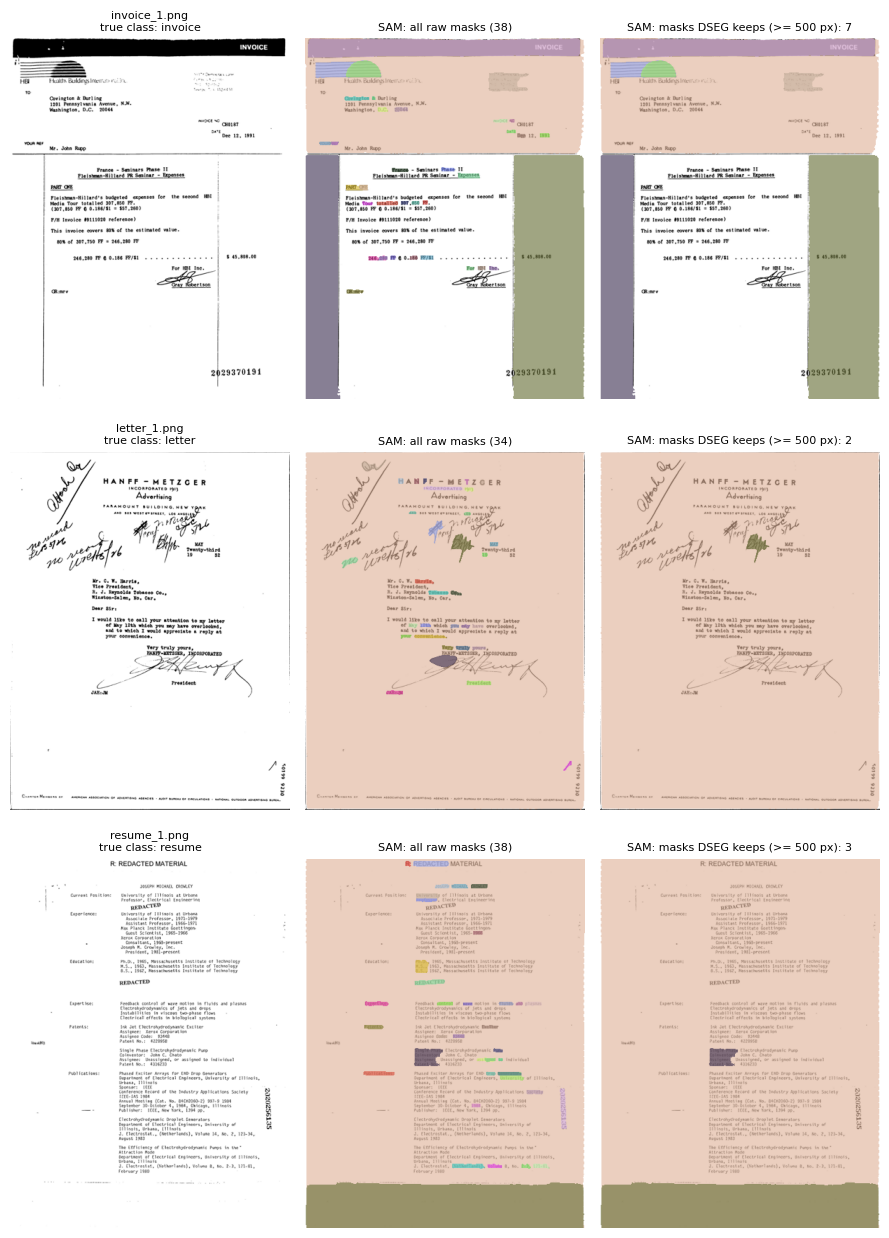

In [5]:
def overlay(img, masks, seed=0):
    rng = np.random.default_rng(seed)
    canvas = img.astype(float)
    for m in sorted(masks, key=lambda m: -m["area"]):       # big first, so small masks stay visible
        seg = m["segmentation"]
        canvas[seg] = 0.4 * canvas[seg] + 0.6 * rng.integers(40, 255, 3)
    return canvas.astype(np.uint8)

first_per_class = {f.rsplit("_", 1)[0]: f for f in DOCS}      # {class: file}

fig, axes = plt.subplots(len(first_per_class), 3, figsize=(9, 4.2 * len(first_per_class)))
for row, (cls, f) in tqdm(zip(axes, first_per_class.items()), total=len(first_per_class), desc="SAM masks"):
    img, _ = load_doc(f)
    raw = mask_generator.generate(img)
    kept, _ = DSEG_Lime().remove_small_clusters(raw, 500, plot=False)
    row[0].imshow(img); row[0].set_title(f"{f}\ntrue class: {cls}", fontsize=8)
    row[1].imshow(overlay(img, raw)); row[1].set_title(f"SAM: all raw masks ({len(raw)})", fontsize=8)
    row[2].imshow(overlay(img, kept)); row[2].set_title(f"SAM: masks DSEG keeps (>= 500 px): {len(kept)}", fontsize=8)
    for a in row: a.axis("off")
plt.tight_layout(); plt.show()

## 2c. The same pages segmented by OCR instead of SAM

`OCRMaskGenerator` (`code/ocr_masks.py`) turns OCR boxes into masks, with the same interface as SAM's mask generator.
DSEG-LIME builds its hierarchy from mask containment, so lines nest inside blocks.

* `BACKEND = "paddle"` (default): PaddleOCR, the OCR family used in the *When superpixels fail on documents* paper.
  It returns text **lines** only, so **blocks are a geometric heuristic** (lines that overlap horizontally and are vertically close are merged), not a layout model.
* `BACKEND = "tesseract"`: native blocks / lines / words.

Words are left out by default: DSEG drops masks under 500 px, which removes most single words at this resolution.

OCR masks:   0%|          | 0/3 [00:00<?, ?it/s]

/Users/ema/projects/hierarchical-attribution/.venv/lib/python3.12/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/ema/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/ema/.paddlex/official_models/PP-OCRv6_medium_rec`.


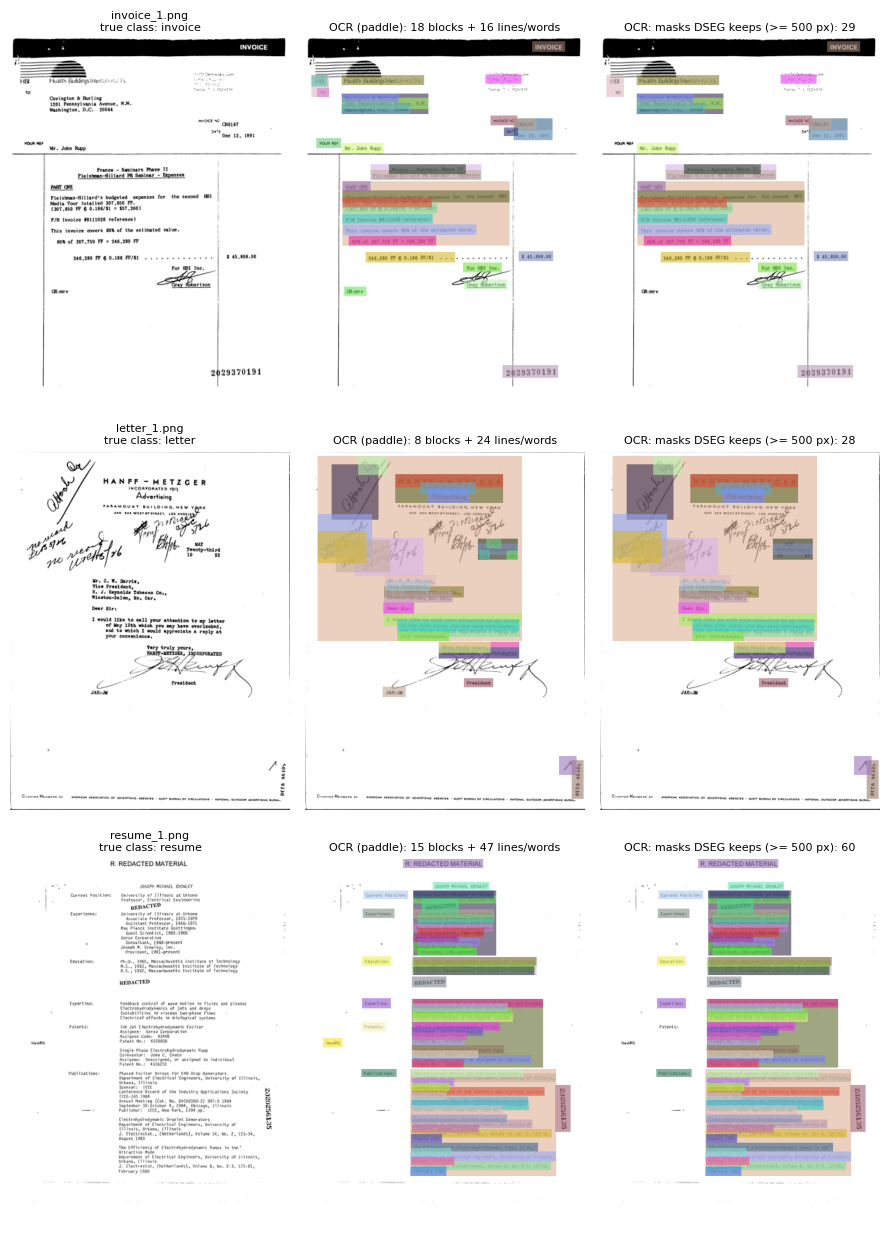

In [6]:
BACKEND = "paddle"                # or "tesseract"
LEVELS = ("block", "line")        # "word" only works with BACKEND = "tesseract"
ocr_generator = OCRMaskGenerator(backend=BACKEND, levels=LEVELS)

fig, axes = plt.subplots(len(first_per_class), 3, figsize=(9, 4.2 * len(first_per_class)))
for row, (cls, f) in tqdm(zip(axes, first_per_class.items()), total=len(first_per_class), desc="OCR masks"):
    img, _ = load_doc(f)
    raw = ocr_generator.generate(img)
    kept, _ = DSEG_Lime().remove_small_clusters(raw, 500, plot=False)
    n_blocks = sum(m["level"] == "block" for m in raw)
    row[0].imshow(img); row[0].set_title(f"{f}\ntrue class: {cls}", fontsize=8)
    row[1].imshow(overlay(img, raw)); row[1].set_title(f"OCR ({BACKEND}): {n_blocks} blocks + {len(raw) - n_blocks} lines/words", fontsize=8)
    row[2].imshow(overlay(img, kept)); row[2].set_title(f"OCR: masks DSEG keeps (>= 500 px): {len(kept)}", fontsize=8)
    for a in row: a.axis("off")
plt.tight_layout(); plt.show()

## 3. One document, step by step: SAM

[('invoice', 0.994), ('budget', 0.005), ('form', 0.001)]


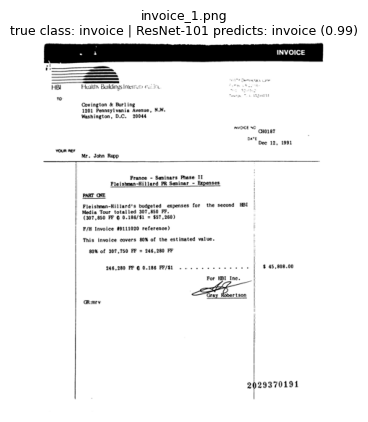

In [7]:
name = "invoice_1.png"
image, path = load_doc(name)
probs = classifier_fn(image[None])[0]
top = probs.argsort()[::-1][:3]
print([(id2label[int(i)], round(float(probs[i]), 3)) for i in top])
plt.imshow(image); plt.axis("off")
plt.title(f"{name}\ntrue class: {name.rsplit('_', 1)[0]} | {MODEL_NAME} predicts: {id2label[int(top[0])]} ({probs[top[0]]:.2f})", fontsize=9)
plt.show()

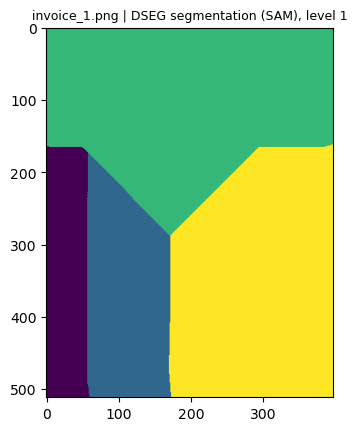

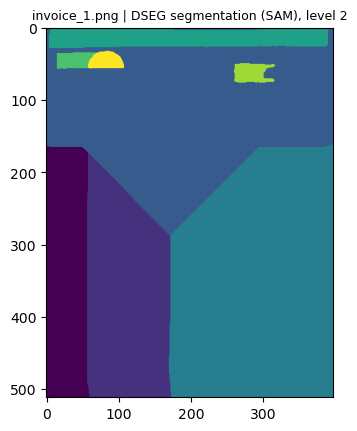

SAM: 46s, 8 segments at the last level


In [8]:
t0 = time.time()
explainer = DSEG_Lime()
with dseg_plots(f"{name} | DSEG segmentation (SAM)"):      # titles the per-level segmentation plots
    exp = explainer.explain_instance(image=image, classifier_fn=classifier_fn,
                                     feature_extractor=mask_generator, model=sam, image_path=path,
                                     num_samples=NUM_SAMPLES, iterations=ITERATIONS, progress_bar=False)
print(f"SAM: {time.time() - t0:.0f}s, {len(np.unique(exp.segments))} segments at the last level")

## 4. Visualise (SAM): segments ranked by LIME coefficient for the predicted class

Green = pushes towards the predicted class, red = pushes against, yellow = close to 0. Every segment is coloured, including the small text boxes. The colour scale is clipped at the 90th percentile of |coefficient| so that one huge segment (often the page background) does not wash out the rest, and it is set per panel, so intensities are not comparable between panels.

explained class: invoice


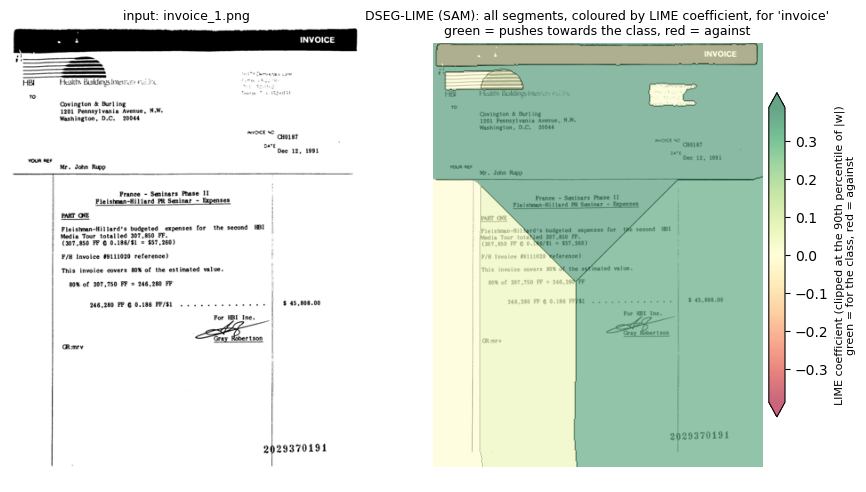

In [9]:
def show(exp, image, label, k=None, ax=None, cbar=False, clip_pct=90):
    """Overlay the LIME coefficient of EVERY segment for `label` (k=None), or only the k largest |coefficients|.
    green = pushes towards the class, red = pushes against, yellow = close to 0.
    The colour scale is symmetric and clipped at the clip_pct-th percentile of |coefficient|, so one huge segment cannot
    wash out the others (values above the clip saturate). It is set per panel, so it is not comparable across panels."""
    ax = ax or plt.gca()
    items = sorted(((t[0], t[1]) for t in exp.local_exp[label]), key=lambda t: -abs(t[1]))   # entries are (segment_id, weight, 0.0)
    items = items[:k] if k else items
    heat = np.full(exp.segments.shape, np.nan)            # NaN = not drawn (only when k is set)
    for sid, w in items:
        heat[exp.segments == sid] = w
    m = float(np.percentile([abs(w) for _, w in items], clip_pct)) or max(abs(w) for _, w in items) or 1.0
    ax.imshow(image)
    im = ax.imshow(np.ma.masked_invalid(heat), cmap="RdYlGn", vmin=-m, vmax=m, alpha=0.6)
    ax.imshow(mark_boundaries(np.zeros(image.shape[:2]), exp.segments.astype(int))[..., 0], cmap="gray_r", alpha=0.25)
    ax.axis("off")
    if cbar:
        c = ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.02, extend="both")
        c.set_label(f"LIME coefficient (clipped at the {clip_pct}th percentile of |w|)\ngreen = for the class, red = against", fontsize=8)

label = exp.top_labels[0]
print("explained class:", id2label[int(label)])
fig, ax = plt.subplots(1, 2, figsize=(10, 7))
ax[0].imshow(image); ax[0].set_title(f"input: {name}", fontsize=9); ax[0].axis("off")
show(exp, image, label, ax=ax[1], cbar=True)
ax[1].set_title(f"DSEG-LIME (SAM): all segments, coloured by LIME coefficient, for '{id2label[int(label)]}'\ngreen = pushes towards the class, red = against", fontsize=9)
plt.show()

## 3b. One document, step by step: OCR

The same page, classifier and settings as section 3, but the segmenter is `ocr_generator` from section 2c (`BACKEND`, PaddleOCR by default) instead of SAM.

[('invoice', 0.994), ('budget', 0.005), ('form', 0.001)] (same page, same classifier as section 3)


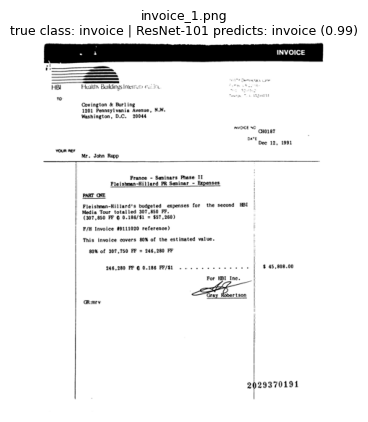

In [10]:
print([(id2label[int(i)], round(float(probs[i]), 3)) for i in top], "(same page, same classifier as section 3)")
plt.imshow(image); plt.axis("off")
plt.title(f"{name}\ntrue class: {name.rsplit('_', 1)[0]} | {MODEL_NAME} predicts: {id2label[int(top[0])]} ({probs[top[0]]:.2f})", fontsize=9)
plt.show()

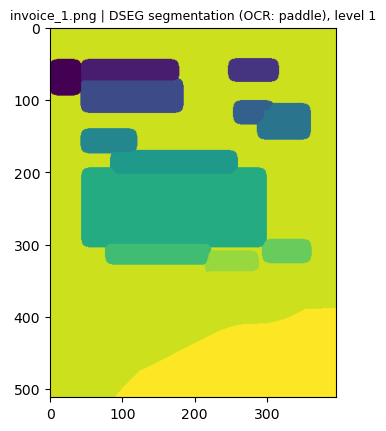

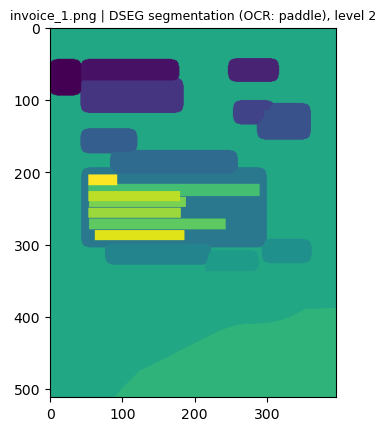

OCR (paddle): 23s, 21 segments at the last level


In [11]:
t0 = time.time()
with dseg_plots(f"{name} | DSEG segmentation (OCR: {BACKEND})"):
    exp_ocr = DSEG_Lime().explain_instance(image=image, classifier_fn=classifier_fn,
                                           feature_extractor=ocr_generator, model=None, image_path=path,
                                           num_samples=NUM_SAMPLES, iterations=ITERATIONS, progress_bar=False)
print(f"OCR ({BACKEND}): {time.time() - t0:.0f}s, {len(np.unique(exp_ocr.segments))} segments at the last level")

## 4b. Visualise (OCR): segments ranked by LIME coefficient for the predicted class

explained class: invoice


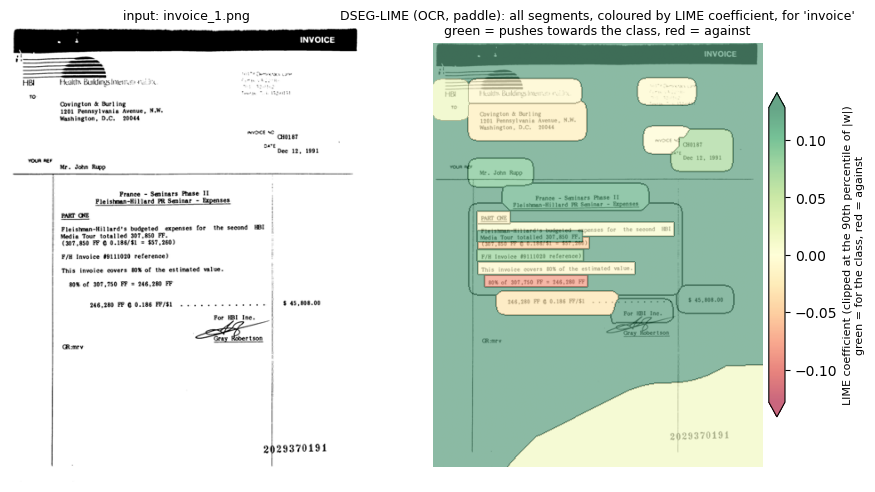

In [12]:
label_ocr = exp_ocr.top_labels[0]
print("explained class:", id2label[int(label_ocr)])
fig, ax = plt.subplots(1, 2, figsize=(10, 7))
ax[0].imshow(image); ax[0].set_title(f"input: {name}", fontsize=9); ax[0].axis("off")
show(exp_ocr, image, label_ocr, ax=ax[1], cbar=True)
ax[1].set_title(f"DSEG-LIME (OCR, {BACKEND}): all segments, coloured by LIME coefficient, for '{id2label[int(label_ocr)]}'\ngreen = pushes towards the class, red = against", fontsize=9)
plt.show()

## 4c. Side by side: SAM vs OCR on this page

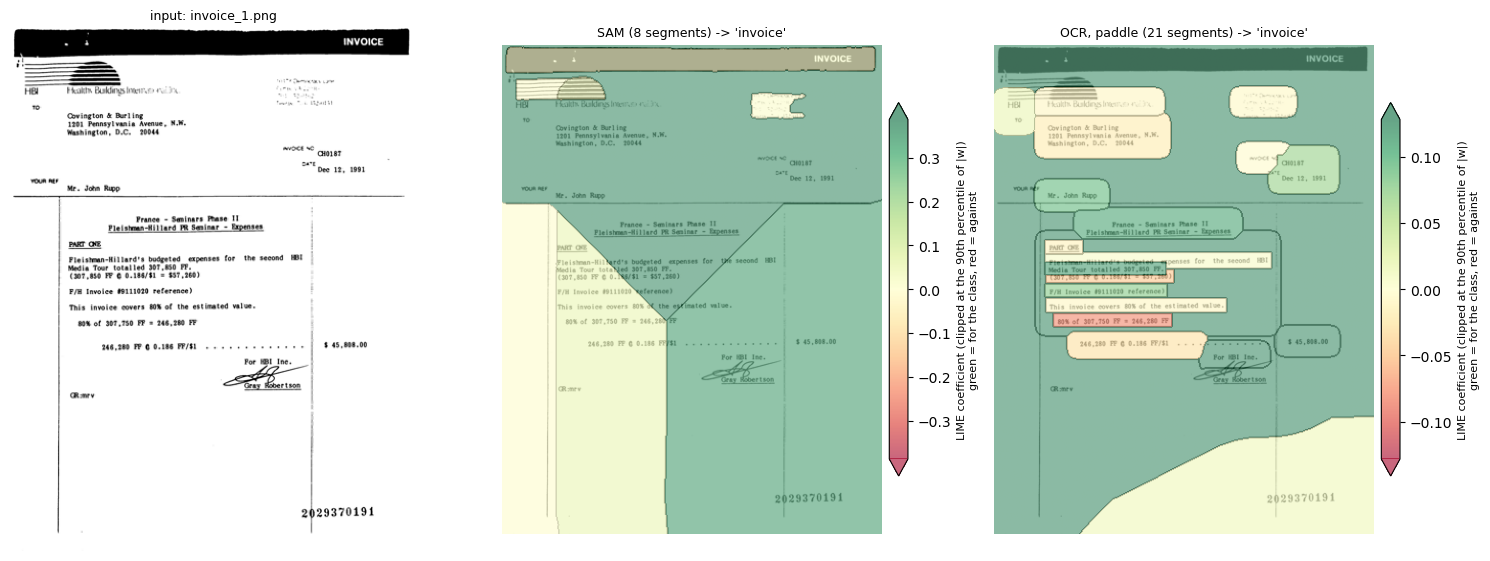

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 7))
ax[0].imshow(image); ax[0].set_title(f"input: {name}", fontsize=9); ax[0].axis("off")
show(exp, image, label, ax=ax[1], cbar=True)
ax[1].set_title(f"SAM ({len(np.unique(exp.segments))} segments) -> '{id2label[int(label)]}'", fontsize=9)
show(exp_ocr, image, label_ocr, ax=ax[2], cbar=True)
ax[2].set_title(f"OCR, {BACKEND} ({len(np.unique(exp_ocr.segments))} segments) -> '{id2label[int(label_ocr)]}'", fontsize=9)
plt.tight_layout(); plt.show()

## 5. The selected documents: SAM

The pages in `DOCS` (setup cell), one per class.

DSEG-LIME (SAM):   0%|          | 0/3 [00:00<?, ?it/s]

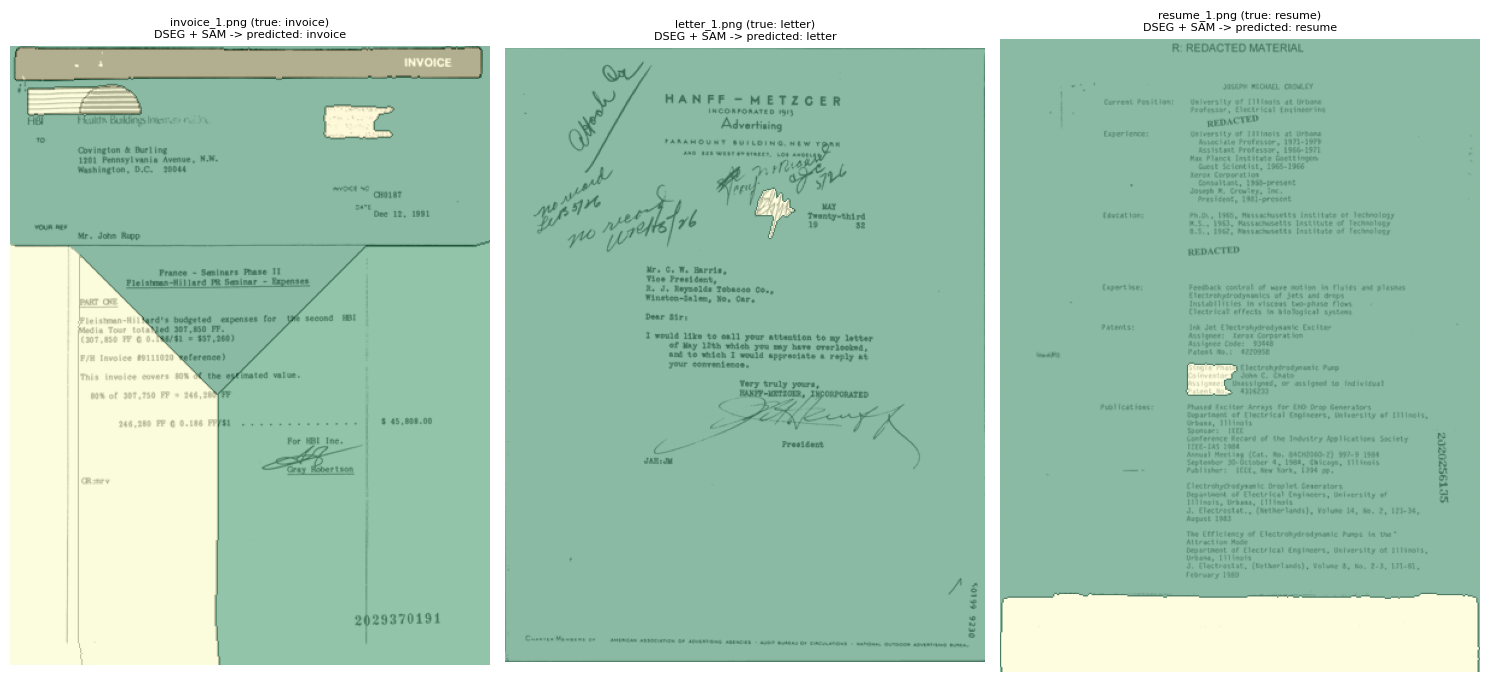

,file,pred,n_segments,local_R2,seconds
0,invoice_1.png,invoice,8,0.824,47
1,letter_1.png,letter,2,0.998,46
2,resume_1.png,resume,3,0.998,43


In [14]:
rows = []
files = DOCS
fig, axes = plt.subplots(1, len(files), figsize=(5 * len(files), 7))
for ax, f in tqdm(zip(np.atleast_1d(axes).ravel(), files), total=len(files), desc="DSEG-LIME (SAM)"):
    img, p = load_doc(f)
    t0 = time.time()
    with dseg_plots(None):
        e = DSEG_Lime().explain_instance(image=img, classifier_fn=classifier_fn, feature_extractor=mask_generator,
                                         model=sam, image_path=p, num_samples=NUM_SAMPLES,
                                         iterations=ITERATIONS, progress_bar=False)
    lab = e.top_labels[0]
    show(e, img, lab, ax=ax); ax.set_title(f"{f} (true: {f.rsplit('_', 1)[0]})\nDSEG + SAM -> predicted: {id2label[int(lab)]}", fontsize=8)
    rows.append({"file": f, "pred": id2label[int(lab)], "n_segments": int(len(np.unique(e.segments))),
                 "local_R2": round(float(e.score[lab]), 3), "seconds": round(time.time() - t0)})
plt.tight_layout(); plt.show()
import pandas as pd; pd.DataFrame(rows)

## 5b. The selected documents: OCR

Same grid and table as section 5, with `ocr_generator` (section 2c, `BACKEND`) as the segmenter instead of SAM.

DSEG-LIME (OCR, paddle):   0%|          | 0/3 [00:00<?, ?it/s]

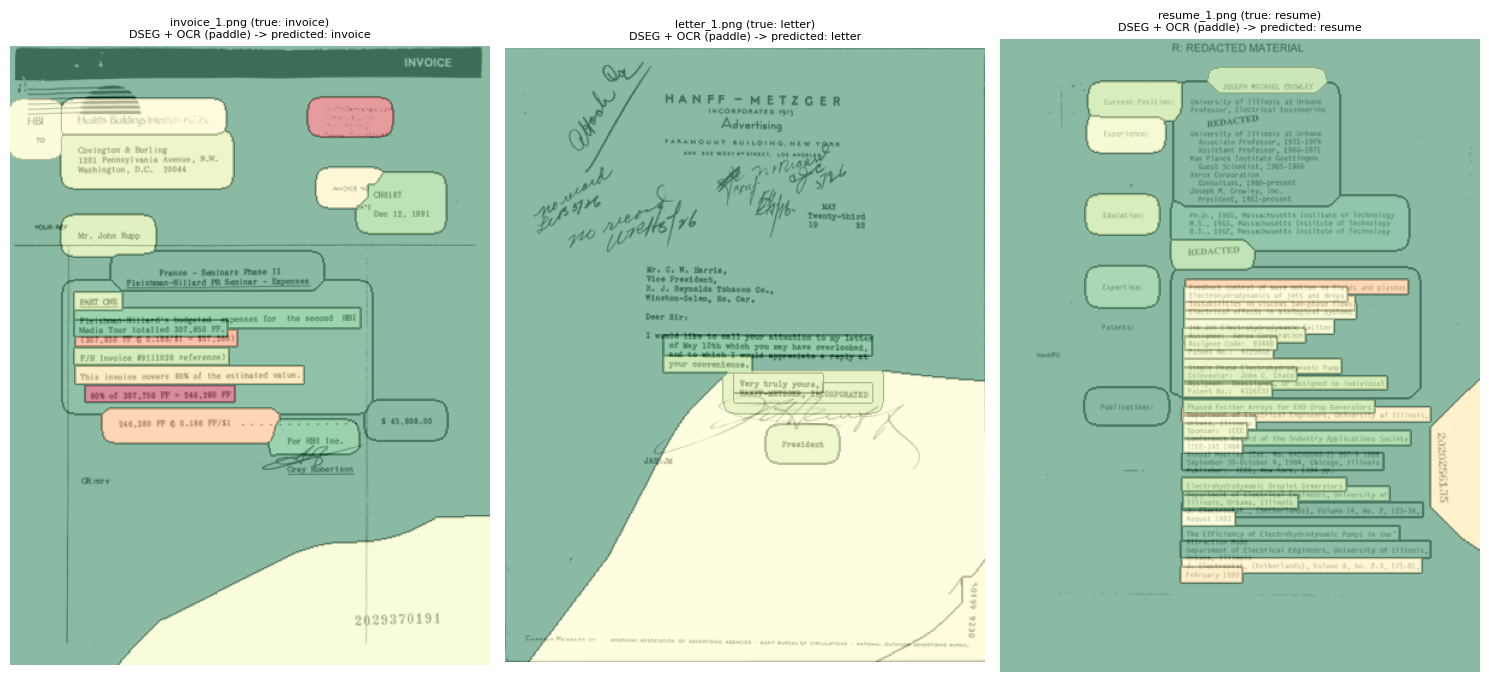

,file,pred,n_segments,local_R2,seconds
0,invoice_1.png,invoice,21,0.734,24
1,letter_1.png,letter,9,0.853,21
2,resume_1.png,resume,40,0.658,29


In [15]:
rows_ocr = []
files = DOCS
fig, axes = plt.subplots(1, len(files), figsize=(5 * len(files), 7))
for ax, f in tqdm(zip(np.atleast_1d(axes).ravel(), files), total=len(files), desc=f"DSEG-LIME (OCR, {BACKEND})"):
    img, p = load_doc(f)
    t0 = time.time()
    with dseg_plots(None):
        e = DSEG_Lime().explain_instance(image=img, classifier_fn=classifier_fn, feature_extractor=ocr_generator,
                                         model=None, image_path=p, num_samples=NUM_SAMPLES,
                                         iterations=ITERATIONS, progress_bar=False)
    lab = e.top_labels[0]
    show(e, img, lab, ax=ax); ax.set_title(f"{f} (true: {f.rsplit('_', 1)[0]})\nDSEG + OCR ({BACKEND}) -> predicted: {id2label[int(lab)]}", fontsize=8)
    rows_ocr.append({"file": f, "pred": id2label[int(lab)], "n_segments": int(len(np.unique(e.segments))),
                     "local_R2": round(float(e.score[lab]), 3), "seconds": round(time.time() - t0)})
plt.tight_layout(); plt.show()
import pandas as pd; pd.DataFrame(rows_ocr)

## 6. SAM vs OCR segments inside DSEG-LIME

Same classifier, same DSEG-LIME code, same settings; only the segmenter changes. One page per class.
`prob_drop_top3` is a quick deletion test: hide the 3 segments with the highest positive coefficient (white) and report how much the
predicted-class probability falls. A bigger drop means the explanation pointed at regions the model really relies on.

SAM vs OCR in DSEG:   0%|          | 0/3 [00:00<?, ?it/s]

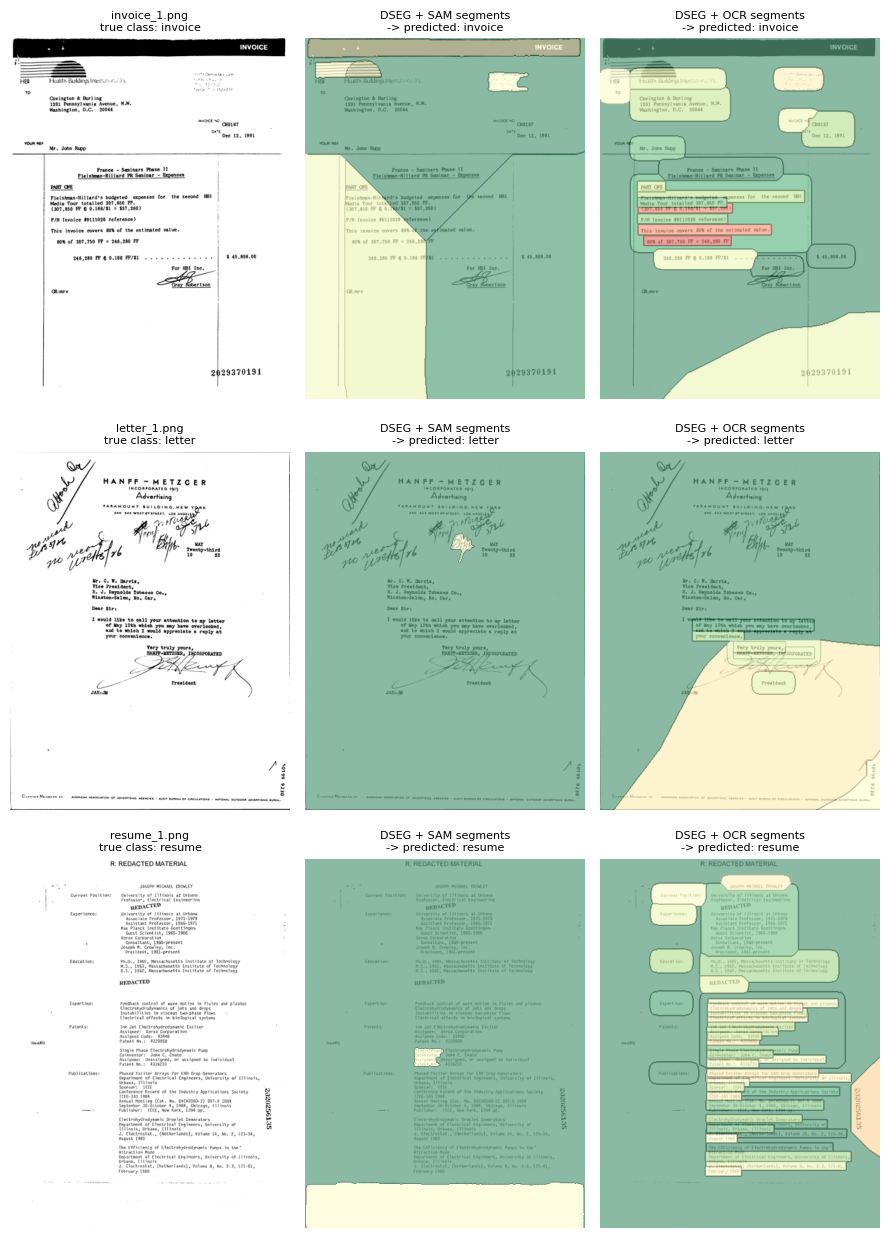

,doc,segmenter,pred,n_segments,local_R2,prob_drop_top3,seconds
0,invoice_1.png,SAM,invoice,8,0.839,0.987,46
1,invoice_1.png,OCR,invoice,21,0.695,0.460,25
2,letter_1.png,SAM,letter,2,0.998,0.937,45
3,letter_1.png,OCR,letter,9,0.830,0.795,21
4,resume_1.png,SAM,resume,3,0.999,0.950,41
5,resume_1.png,OCR,resume,40,0.636,0.053,29


,n_segments,local_R2,prob_drop_top3,seconds
segmenter,,,,
OCR,23.333,0.720,0.436,25.0
SAM,4.333,0.945,0.958,44.0


In [16]:
def prob_drop_top3(e, img, label, k=3):
    pos = sorted(((t[0], t[1]) for t in e.local_exp[label] if t[1] > 0), key=lambda t: -t[1])[:k]
    hidden = img.copy()
    for sid, _ in pos:
        hidden[e.segments == sid] = 255
    p0, p1 = classifier_fn(np.stack([img, hidden]))[:, label]
    return float(p0 - p1)

cmp_rows = []
fig, axes = plt.subplots(len(first_per_class), 3, figsize=(9, 4.2 * len(first_per_class)))
for row, (cls, f) in tqdm(zip(axes, first_per_class.items()), total=len(first_per_class), desc="SAM vs OCR in DSEG"):
    img, p = load_doc(f)
    row[0].imshow(img); row[0].set_title(f"{f}\ntrue class: {cls}", fontsize=8); row[0].axis("off")
    for ax, (name, gen, mdl) in zip(row[1:], [("SAM", mask_generator, sam), ("OCR", ocr_generator, None)]):
        t0 = time.time()
        with dseg_plots(None):
            e = DSEG_Lime().explain_instance(image=img, classifier_fn=classifier_fn, feature_extractor=gen, model=mdl,
                                             image_path=p, num_samples=NUM_SAMPLES, iterations=ITERATIONS, progress_bar=False)
        lab = e.top_labels[0]
        show(e, img, lab, ax=ax); ax.set_title(f"DSEG + {name} segments\n-> predicted: {id2label[int(lab)]}", fontsize=8)
        cmp_rows.append({"doc": f, "segmenter": name, "pred": id2label[int(lab)],
                         "n_segments": int(len(np.unique(e.segments))), "local_R2": round(float(e.score[lab]), 3),
                         "prob_drop_top3": round(prob_drop_top3(e, img, lab), 3), "seconds": round(time.time() - t0)})
plt.tight_layout(); plt.show()
import pandas as pd
df = pd.DataFrame(cmp_rows); display(df)
df.groupby("segmenter")[["n_segments", "local_R2", "prob_drop_top3", "seconds"]].mean().round(3)

## Notes

* DSEG-LIME builds its hierarchy from the overlap between masks (a containment graph). With SAM the units are generic objects and blobs; with OCR they are text blocks and lines.
* At each level DSEG refines the **top 2** segments by coefficient into their children and fits LIME again; only the **last** level is returned, and the levels are fitted independently.
* `local_R2` is LIME's own weighted R² of the surrogate on the neighbourhood (a local-fidelity proxy).
* DSEG drops masks under 500 px (`Utilities/dseg_lime.py`, hard-coded); at `MAX_SIDE = 512` that removes small OCR boxes, and most single words.
* SAM yields only ~6-8 usable masks on a 512 px invoice (after that filter).
* Hide colour: the baseline default (mean colour per segment) is kept.